# 02a – EUBUCCO extract for the whole municipality (MOL)

Špela's extract (used in the first run of 02) covers only the **settlement** Ljubljana (164 km²), not the whole municipality **MOL** (275 km²).
About 885 populated edge cells had no building data, and only 16,369 of 27,505 cells could be clustered.

Here we cut MOL out of the EUBUCCO v0.2 file for western Slovenia (NUTS 2 region **SI04**, 524,000 buildings):
1. load the MOL boundary (the same file that defines the grid) and convert it to EPSG:3035, the CRS of EUBUCCO
2. read only buildings inside the bounding box of MOL (fast pre-filter)
3. keep buildings that **intersect** the boundary – buildings crossing the border are kept whole, the grid cells at the border need them
4. convert to D96/TM (EPSG:3794), rename the columns to the short names used in Špela's extract, add `area_m2` and `perim_m`
5. compare with Špela's extract: the buildings she has should be identical in our extract

- **Input:** `data/raw/LJ_EUBBUCO/SI04.gpkg` (EUBUCCO v0.2, downloaded 1 Nov 2026), `data/raw/LJ_prebivalstvo_MOL_100m_2025/obcina_ljubljana.gpkg`
- **Output:** `data/processed/eubucco_mol.gpkg` with layers `buildings` and `boundary` (same structure as Špela's file, so 02 works unchanged)

## 1. Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"

SOURCE = RAW / "LJ_EUBBUCO" / "SI04.gpkg"
OLD_EXTRACT = RAW / "LJ_EUBBUCO" / "ljubljana_eubucco_v02.gpkg"
MOL = RAW / "LJ_prebivalstvo_MOL_100m_2025" / "obcina_ljubljana.gpkg"
OUT = PROCESSED / "eubucco_mol.gpkg"

# Full EUBUCCO names -> short names used in Špela's extract (and in 02)
RENAME = {
    "construction_year": "const_yr",
    "type_confidence": "t_conf", "subtype_confidence": "s_conf",
    "height_confidence_lower": "h_conf_lo", "height_confidence_upper": "h_conf_hi",
    "floors_confidence_lower": "f_conf_lo", "floors_confidence_upper": "f_conf_hi",
    "construction_year_confidence_lower": "c_conf_lo", "construction_year_confidence_upper": "c_conf_hi",
    "geometry_source": "geom_src", "type_source": "t_src", "subtype_source": "s_src",
    "height_source": "h_src", "floors_source": "f_src", "construction_year_source": "c_src",
    "geometry_source_id": "geom_sid", "type_source_ids": "t_sids", "subtype_source_ids": "s_sids",
    "height_source_ids": "h_sids", "floors_source_ids": "f_sids", "construction_year_source_ids": "c_sids",
    "subtype_raw": "s_raw",
}

## 2. MOL boundary and pre-filter by bounding box

In [2]:
mol = gpd.read_file(MOL)
mol_3035 = mol.to_crs(3035)
print(f"MOL: {mol.area.sum() / 1e6:.0f} km²")

xmin, ymin, xmax, ymax = mol_3035.total_bounds
bld = gpd.read_file(SOURCE, bbox=(xmin, ymin, xmax, ymax))
print(f"Buildings in the bounding box of MOL: {len(bld):,}")

C:\Users\Maks\miniforge3\envs\urban\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


MOL: 275 km²


Buildings in the bounding box of MOL: 114,407


## 3. Exact clip
`intersects` keeps every building that touches MOL, including those crossing the border. We also count how many lie completely inside, to see how many are border buildings.

In [3]:
shape_3035 = mol_3035.union_all()
bld = bld[bld.intersects(shape_3035)].copy()
crossing = ~bld.within(shape_3035)
print(f"Buildings intersecting MOL: {len(bld):,}  (crossing the border: {crossing.sum():,})")

bld = bld.to_crs(3794).rename(columns=RENAME)
bld["area_m2"] = bld.area.round(1)
bld["perim_m"] = bld.length.round(1)
print("Regions:", bld["region_id"].value_counts().to_dict())
print("Duplicate ids:", bld["id"].duplicated().sum())

Buildings intersecting MOL: 82,495  (crossing the border: 12)


Regions: {'SI041': 82495}
Duplicate ids: 0


## 4. Compare with Špela's extract
- Same columns?
- Are all her buildings in our extract, and are their attributes the same? If yes, the new data is a pure extension of the old one,
  and inside the settlement the indicators from 02 should not change.

In [4]:
old = gpd.read_file(OLD_EXTRACT, layer="buildings")
old_extent = gpd.read_file(OLD_EXTRACT, layer="boundary")
print("Columns only in old:", sorted(set(old.columns) - set(bld.columns)))
print("Columns only in new:", sorted(set(bld.columns) - set(old.columns)))

common = old["id"].isin(bld["id"])
print(f"\nOld buildings found in new extract: {common.sum():,} of {len(old):,}")
print(f"New buildings: {len(bld):,}  (+{len(bld) - len(old):,})")

a = old.set_index("id").loc[old.loc[common, "id"]]
b = bld.set_index("id").loc[a.index]
for col in ["type", "subtype", "height", "floors", "geom_src", "h_src"]:
    same = (a[col] == b[col]) | (a[col].isna() & b[col].isna())
    print(f"  {col:10s} identical: {same.mean():.2%}")
print(f"  area_m2    max abs difference: {(a['area_m2'] - b['area_m2']).abs().max():.2f} m²")

Columns only in old: []
Columns only in new: []

Old buildings found in new extract: 75,060 of 75,061
New buildings: 82,495  (+7,434)
  type       identical: 100.00%


  subtype    identical: 100.00%
  height     identical: 100.00%
  floors     identical: 100.00%
  geom_src   identical: 100.00%
  h_src      identical: 100.00%
  area_m2    max abs difference: 0.00 m²


## 5. Data quality: inside vs outside the settlement
The new buildings are on the edge of MOL (villages, hills, Barje). Their data quality may differ from the city: more Microsoft footprints, more estimated heights.

In [5]:
bld["in_settlement"] = bld["id"].isin(old["id"])
for col in ["geom_src", "h_src", "t_src"]:
    print(col)
    print(pd.crosstab(bld[col], bld["in_settlement"].map({True: "settlement (old)", False: "new (outside)"}),
                      normalize="columns").round(2).to_string(), "\n")
print(bld.groupby("in_settlement")[["height", "area_m2"]].describe().round(1).T.to_string())
print(f"\nHeights > 90 m (cleaned in 02): {(bld['height'] > 90).sum()}")
print(f"Missing height: {bld['height'].isna().sum()},  missing type: {bld['type'].isna().sum()}")

geom_src


in_settlement  new (outside)  settlement (old)
geom_src                                      
gov-slovenia            0.77              0.87
msft                    0.13              0.08
osm                     0.09              0.05 

h_src
in_settlement  new (outside)  settlement (old)
h_src                                         
estimated               0.29               0.2
gov-slovenia            0.71               0.8
osm                     0.00               0.0 

t_src
in_settlement  new (outside)  settlement (old)
t_src                                         
estimated               0.77              0.67
osm                     0.23              0.33 

in_settlement   False     True 
height  count  7435.0   75060.0
        mean      6.3       6.8
        std       2.4       5.6
        min       1.5       1.5
        25%       4.2       3.6
        50%       6.0       6.1
        75%       8.1       8.9
        max      25.4     318.3
area_m2 count  7435.0   75060.0
    

## 6. Map

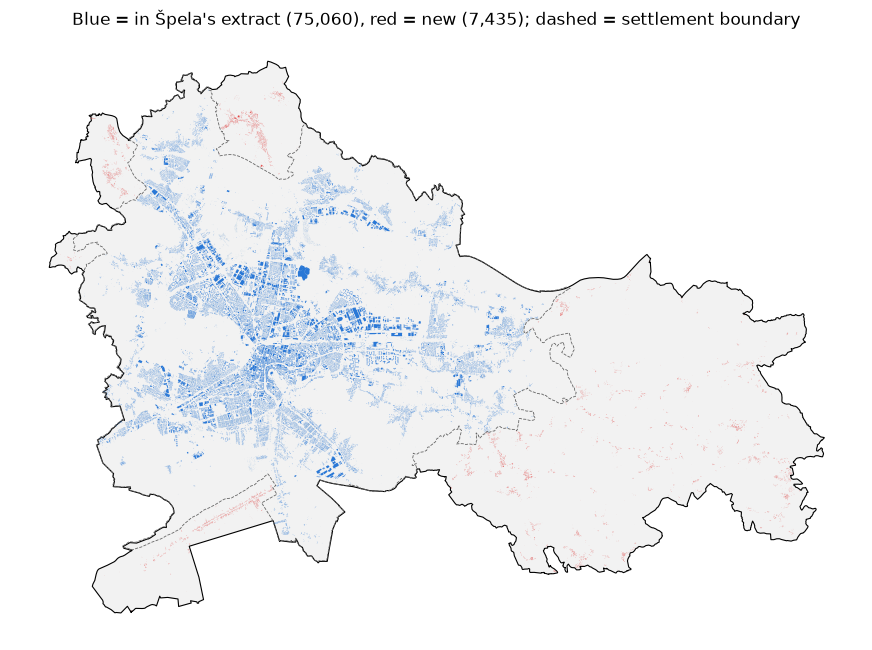

In [6]:
fig, ax = plt.subplots(figsize=(11, 9))
mol.plot(ax=ax, color="#f2f2f2", edgecolor="black", linewidth=0.8)
bld[bld["in_settlement"]].plot(ax=ax, color="#2a78d6", linewidth=0)
bld[~bld["in_settlement"]].plot(ax=ax, color="#e34948", linewidth=0)
old_extent.boundary.plot(ax=ax, color="#666666", linewidth=0.6, linestyle="--")
ax.set_title(f"Blue = in Špela's extract ({bld['in_settlement'].sum():,}), red = new ({(~bld['in_settlement']).sum():,}); dashed = settlement boundary")
ax.set_axis_off()
plt.show()

## 7. Save

In [7]:
OUT.unlink(missing_ok=True)
bld.drop(columns="in_settlement").to_file(OUT, layer="buildings", driver="GPKG")
mol[["geometry"]].to_file(OUT, layer="boundary", driver="GPKG")
print(f"Saved {len(bld):,} buildings + MOL boundary to {OUT.name}")

C:\Users\Maks\miniforge3\envs\urban\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Cannot find tms_NZTM2000.json (GDAL_DATA is not defined)
  ogr_write(


Saved 82,495 buildings + MOL boundary to eubucco_mol.gpkg
